In [2]:
# Choose python environment. If doesn't work use this --->>   
# (1) python -m venv .venv 
# (2) .venv\Scripts\Activate.ps1

In [3]:
# Set-up/ intall packages.
%pip install "kagglehub[pandas-datasets]" pandas numpy matplotlib seaborn scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [4]:
# Import installed packages/ libraries into environment?
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub as kh
import zipfile
from pathlib import Path

In [5]:
# Set-up folders --- data and figures --- relative paths to enable the notebook to work on any computer.

DATA_DIR = Path("data")      # raw and clean CSV files go here
FIG_DIR = Path("figures")    # exported plots go here

DATA_DIR.mkdir(exist_ok=True)  # create the folder if it does not exist yet
FIG_DIR.mkdir(exist_ok=True)

In [6]:
# pandas display options 
pd.set_option("display.max_columns", 50)                 # show every column, do not hide them with "..."
pd.set_option("display.float_format", "{:,.2f}".format)  # 1234567.891 -> 1,234,567.89

# plot style 
sns.set_theme(style="whitegrid", context="notebook")  # clean background with a light grid
plt.rcParams["figure.figsize"] = (10, 5)              # default size of every figure (width, height) in inches

# Seed for anything random (sampling): the same seed always gives the same "random" result,
# so everybody in class sees exactly the same numbers.
RANDOM_STATE = 42

In [7]:
# "save_fig()" exports plots as .png 
# Creating a function to call when we need to save a figure (plot during analysis) onto the computer.

def save_fig(name):
    # Save the current figure as a PNG inside FIG_DIR.
    # dpi = dots per inch (resolution). bbox_inches="tight" trims empty white borders.
    path = FIG_DIR / f"{name}.png"
    plt.savefig(path, dpi=150, bbox_inches="tight")
    print(f"Figure saved to {path}")

In [8]:
# Import csv file from data folder.
df = pd.read_csv(
    DATA_DIR / "global_city_col_qol_index.csv"
)

# print info of imported csv data --- check
print(f"Loaded {df.shape[0]:,} rows and {df.shape[1]} columns")

Loaded 296 rows and 26 columns


In [9]:
# The first 5 rows.
df.head()

,city_id,city,country,region,subregion,development_tier,population_millions,currency_code,survey_date,cost_of_living_index,rent_index,groceries_index,restaurant_price_index,local_purchasing_power_index,avg_monthly_net_salary_usd,housing_price_to_income_ratio,health_care_index,safety_index,pollution_index,traffic_commute_index,climate_index,internet_speed_mbps,quality_of_life_index,qol_category,data_source_pattern,analyst_note
0,112,Abidjan,Cote d'Ivoire,Africa,Western Africa,4,4.89,XOF,2023-06-15,43.29,24.06,43.18,46.49,38.45,"1,650.87",18.48,29.59,49.52,86.13,61.74,85.79,38.10,42.92,Medium,Synthetic-Numbeo-pattern,NaN
1,112,Abidjan,Cote d'Ivoire,Africa,Western Africa,4,4.89,XOF,2024-06-15,51.53,26.11,47.59,46.68,43.25,"1,826.78",20.84,22.86,49.85,86.33,63.21,63.07,47.30,32.57,Low,Synthetic-EIU-pattern,New infrastructure projects may improve traffi...
2,76,Abu Dhabi,United Arab Emirates,Asia,Western Asia,1,3.22,AED,2023-06-15,100.39,61.19,86.04,64.62,111.37,"6,040.30",8.82,96.34,94.67,38.15,32.22,83.63,168.40,82.84,Very High,Synthetic-EIU-pattern,NaN
3,76,Abu Dhabi,United Arab Emirates,Asia,Western Asia,1,3.22,AED,2024-06-15,95.65,78.33,98.88,84.45,109.32,"6,363.54",10.11,89.47,56.12,28.94,29.20,31.57,NaN,59.92,High,Synthetic-Mercer-pattern,NaN
4,99,Abuja,Nigeria,Africa,Western Africa,4,2.64,NGN,2023-06-15,46.82,32.79,29.90,39.25,49.86,"2,186.81",18.82,38.37,47.52,78.13,65.04,58.49,81.90,38.86,Medium,Synthetic-EIU-pattern,Cost gap between city center and suburbs is wi...


In [10]:
# Column names, data types (Dtype) and number of non-missing values per column
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 296 entries, 0 to 295
Data columns (total 26 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   city_id                        296 non-null    int64  
 1   city                           296 non-null    object 
 2   country                        296 non-null    object 
 3   region                         296 non-null    object 
 4   subregion                      296 non-null    object 
 5   development_tier               296 non-null    int64  
 6   population_millions            296 non-null    float64
 7   currency_code                  296 non-null    object 
 8   survey_date                    296 non-null    object 
 9   cost_of_living_index           296 non-null    float64
 10  rent_index                     296 non-null    float64
 11  groceries_index                296 non-null    float64
 12  restaurant_price_index         296 non-null    flo

In [11]:
# .T transposes the table (rows <-> columns) so it is easier to read with many columns
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
city_id,296.00,NaN,NaN,NaN,74.50,42.80,1.00,37.75,74.50,111.25,148.00
city,296,148,Abidjan,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
country,296,92,United States,24,NaN,NaN,NaN,NaN,NaN,NaN,NaN
region,296,5,Europe,92,NaN,NaN,NaN,NaN,NaN,NaN,NaN
subregion,296,17,Northern America,34,NaN,NaN,NaN,NaN,NaN,NaN,NaN
development_tier,296.00,NaN,NaN,NaN,2.26,1.13,1.00,1.00,2.00,3.00,4.00
population_millions,296.00,NaN,NaN,NaN,5.10,6.00,0.31,1.94,3.13,5.60,38.00
currency_code,296,75,EUR,48,NaN,NaN,NaN,NaN,NaN,NaN,NaN
survey_date,296,2,2023-06-15,148,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cost_of_living_index,296.00,NaN,NaN,NaN,75.16,22.31,23.54,58.85,76.97,94.70,113.29


In [12]:
# .copy() creates an independent copy: changing df_clean will NOT change df
df_clean = df.copy()

In [13]:
# # Give new names to columns if they are not proper.
# new_names = {"Old_Name":"new_name",
#              "Old_Name_2":"new_name_2"}
# df_clean = df_clean.rename(columns=new_names)
# df_clean.columns.tolist()

In [14]:
#Check for duplicates rows in the table
n_duplicates = df_clean.duplicated().sum()
print(f"Number of duplicate rows: {n_duplicates}")

Number of duplicate rows: 0


In [15]:
#check for missing data in the table(n=missing) and percentage of missing data in the table(pct_missing)
def missing_report(data):
    n_missing = data.isnull().sum()
    pct_missing = (n_missing / len(data)) * 100
    report = pd.DataFrame({
        "n_missing": n_missing,
        "pct_missing": pct_missing  
    })
    return report.sort_values(
        "pct_missing", 
        ascending=False
    )
missing = missing_report(df_clean)
missing

,n_missing,pct_missing
analyst_note,193,65.20
internet_speed_mbps,11,3.72
climate_index,11,3.72
traffic_commute_index,11,3.72
housing_price_to_income_ratio,11,3.72
avg_monthly_net_salary_usd,11,3.72
city,0,0.00
data_source_pattern,0,0.00
qol_category,0,0.00
quality_of_life_index,0,0.00


Figure saved to figures\01_missing_values.png


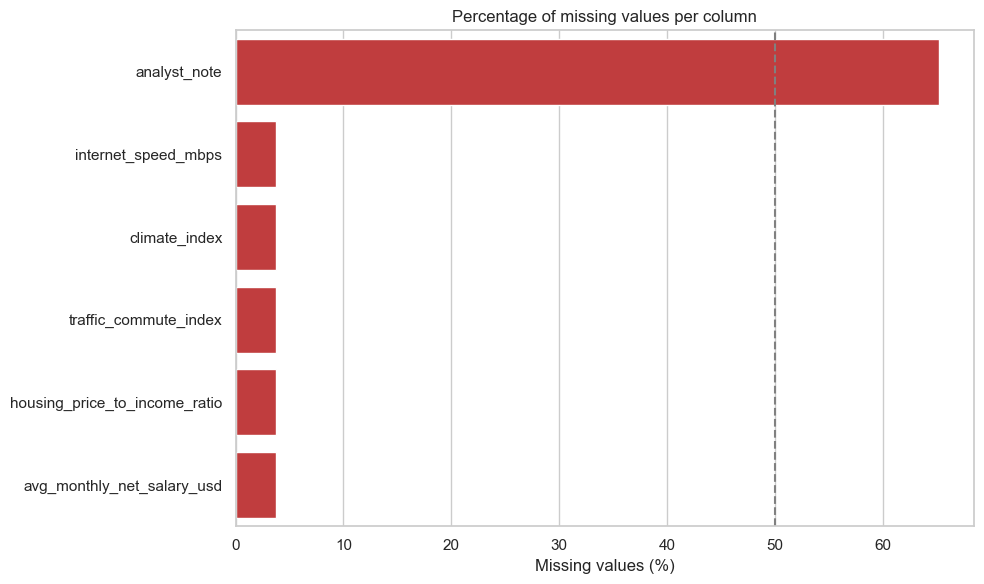

In [16]:
# Easy to understand this with a chart if there is any missing data.
# NONE in this case.

fig, ax = plt.subplots(figsize=(10, 6))

# Only plot the columns that have at least one missing value
missing_to_plot = missing[missing["pct_missing"] > 0]

sns.barplot(data=missing_to_plot, x="pct_missing", y=missing_to_plot.index, color="tab:red", ax=ax)
ax.axvline(50, color="grey", linestyle="--")   # reference line at 50%
ax.set_title("Percentage of missing values per column")
ax.set_xlabel("Missing values (%)")
ax.set_ylabel("")
plt.tight_layout()
save_fig("01_missing_values")
plt.show()

# Can decide what columns to drop based on this analysis.

In [17]:
#column removal for missing data
columns_to_drop = ["analyst_note",
                   "data_source_pattern"]

df_clean = df_clean.drop(columns=columns_to_drop, errors="ignore")

print(
    f"Remaining columns ({df_clean.shape[1]}): "
    f"{df_clean.columns.tolist()}"
)

Remaining columns (24): ['city_id', 'city', 'country', 'region', 'subregion', 'development_tier', 'population_millions', 'currency_code', 'survey_date', 'cost_of_living_index', 'rent_index', 'groceries_index', 'restaurant_price_index', 'local_purchasing_power_index', 'avg_monthly_net_salary_usd', 'housing_price_to_income_ratio', 'health_care_index', 'safety_index', 'pollution_index', 'traffic_commute_index', 'climate_index', 'internet_speed_mbps', 'quality_of_life_index', 'qol_category']


In [18]:
# Check new dataset scope.

print(f"Reduced data scope: {len(df_clean)}")
df_clean.head()

Reduced data scope: 296


,city_id,city,country,region,subregion,development_tier,population_millions,currency_code,survey_date,cost_of_living_index,rent_index,groceries_index,restaurant_price_index,local_purchasing_power_index,avg_monthly_net_salary_usd,housing_price_to_income_ratio,health_care_index,safety_index,pollution_index,traffic_commute_index,climate_index,internet_speed_mbps,quality_of_life_index,qol_category
0,112,Abidjan,Cote d'Ivoire,Africa,Western Africa,4,4.89,XOF,2023-06-15,43.29,24.06,43.18,46.49,38.45,"1,650.87",18.48,29.59,49.52,86.13,61.74,85.79,38.10,42.92,Medium
1,112,Abidjan,Cote d'Ivoire,Africa,Western Africa,4,4.89,XOF,2024-06-15,51.53,26.11,47.59,46.68,43.25,"1,826.78",20.84,22.86,49.85,86.33,63.21,63.07,47.30,32.57,Low
2,76,Abu Dhabi,United Arab Emirates,Asia,Western Asia,1,3.22,AED,2023-06-15,100.39,61.19,86.04,64.62,111.37,"6,040.30",8.82,96.34,94.67,38.15,32.22,83.63,168.40,82.84,Very High
3,76,Abu Dhabi,United Arab Emirates,Asia,Western Asia,1,3.22,AED,2024-06-15,95.65,78.33,98.88,84.45,109.32,"6,363.54",10.11,89.47,56.12,28.94,29.20,31.57,NaN,59.92,High
4,99,Abuja,Nigeria,Africa,Western Africa,4,2.64,NGN,2023-06-15,46.82,32.79,29.90,39.25,49.86,"2,186.81",18.82,38.37,47.52,78.13,65.04,58.49,81.90,38.86,Medium


In [19]:
# check the info and data types of each column in the cleaned table
df_clean.info()
df_clean.describe(include="all").T

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 296 entries, 0 to 295
Data columns (total 24 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   city_id                        296 non-null    int64  
 1   city                           296 non-null    object 
 2   country                        296 non-null    object 
 3   region                         296 non-null    object 
 4   subregion                      296 non-null    object 
 5   development_tier               296 non-null    int64  
 6   population_millions            296 non-null    float64
 7   currency_code                  296 non-null    object 
 8   survey_date                    296 non-null    object 
 9   cost_of_living_index           296 non-null    float64
 10  rent_index                     296 non-null    float64
 11  groceries_index                296 non-null    float64
 12  restaurant_price_index         296 non-null    flo

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
city_id,296.00,NaN,NaN,NaN,74.50,42.80,1.00,37.75,74.50,111.25,148.00
city,296,148,Abidjan,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
country,296,92,United States,24,NaN,NaN,NaN,NaN,NaN,NaN,NaN
region,296,5,Europe,92,NaN,NaN,NaN,NaN,NaN,NaN,NaN
subregion,296,17,Northern America,34,NaN,NaN,NaN,NaN,NaN,NaN,NaN
development_tier,296.00,NaN,NaN,NaN,2.26,1.13,1.00,1.00,2.00,3.00,4.00
population_millions,296.00,NaN,NaN,NaN,5.10,6.00,0.31,1.94,3.13,5.60,38.00
currency_code,296,75,EUR,48,NaN,NaN,NaN,NaN,NaN,NaN,NaN
survey_date,296,2,2023-06-15,148,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cost_of_living_index,296.00,NaN,NaN,NaN,75.16,22.31,23.54,58.85,76.97,94.70,113.29


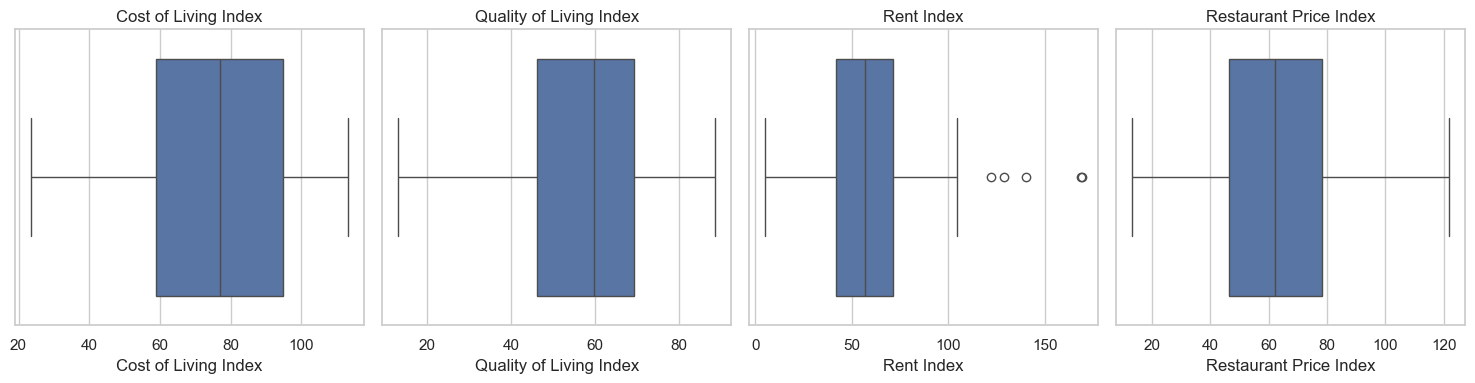

In [20]:
# inspect the distribution of the remaining numeric columns using boxplots to identify outliers and understand the spread of the data.

# Box -> Middle 50% of values
# Line inside the box ->	Median—the middle value
# Whiskers->Range defined by the boxplot rule
# Dots beyond the whiskers -> Potential outliers to investigate

fig, axes = plt.subplots(1, 4, figsize=(15, 4))

sns.boxplot(x=df_clean["cost_of_living_index"], ax=axes[0])
axes[0].set_title("Cost of Living Index")
axes[0].set_xlabel("Cost of Living Index")

sns.boxplot(x=df_clean["quality_of_life_index"], ax=axes[1])
axes[1].set_title("Quality of Living Index")
axes[1].set_xlabel("Quality of Living Index")

sns.boxplot(x=df_clean["rent_index"], ax=axes[2])
axes[2].set_title("Rent Index")
axes[2].set_xlabel("Rent Index")

sns.boxplot(x=df_clean["restaurant_price_index"], ax=axes[3])
axes[3].set_title("Restaurant Price Index")
axes[3].set_xlabel("Restaurant Price Index")

plt.tight_layout()
plt.savefig(FIG_DIR / "01_BoxPlot.png") #save fig
plt.show()


In [21]:
# This block loops through quantitative fields and caps outliers

# Select only numeric columns
numeric_cols = df_clean.select_dtypes(include=['number']).columns

# Loop through each numeric column and cap outliers
for col in numeric_cols:
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)
    IQR = Q3 - Q1
    
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

# Optional: Print the calculated boundaries for transparency
    print(f"Column '{col}' Bounds -> Lower: {lower_bound:.2f}, Upper: {upper_bound:.2f}")
    
    # Cap values outside the bounds
    df_clean[col] = df_clean[col].clip(lower=lower_bound, upper=upper_bound)


print (df_clean.head(10))

Column 'city_id' Bounds -> Lower: -72.50, Upper: 221.50
Column 'development_tier' Bounds -> Lower: -2.00, Upper: 6.00
Column 'population_millions' Bounds -> Lower: -3.56, Upper: 11.10
Column 'cost_of_living_index' Bounds -> Lower: 5.08, Upper: 148.47
Column 'rent_index' Bounds -> Lower: -2.09, Upper: 115.57
Column 'groceries_index' Bounds -> Lower: 4.59, Upper: 128.82
Column 'restaurant_price_index' Bounds -> Lower: -1.80, Upper: 126.58
Column 'local_purchasing_power_index' Bounds -> Lower: -0.51, Upper: 159.19
Column 'avg_monthly_net_salary_usd' Bounds -> Lower: -1214.37, Upper: 9793.84
Column 'housing_price_to_income_ratio' Bounds -> Lower: 0.76, Upper: 26.20
Column 'health_care_index' Bounds -> Lower: -3.58, Upper: 131.99
Column 'safety_index' Bounds -> Lower: 8.43, Upper: 114.52
Column 'pollution_index' Bounds -> Lower: 2.06, Upper: 96.05
Column 'traffic_commute_index' Bounds -> Lower: 7.39, Upper: 85.31
Column 'climate_index' Bounds -> Lower: 16.77, Upper: 101.12
Column 'internet_

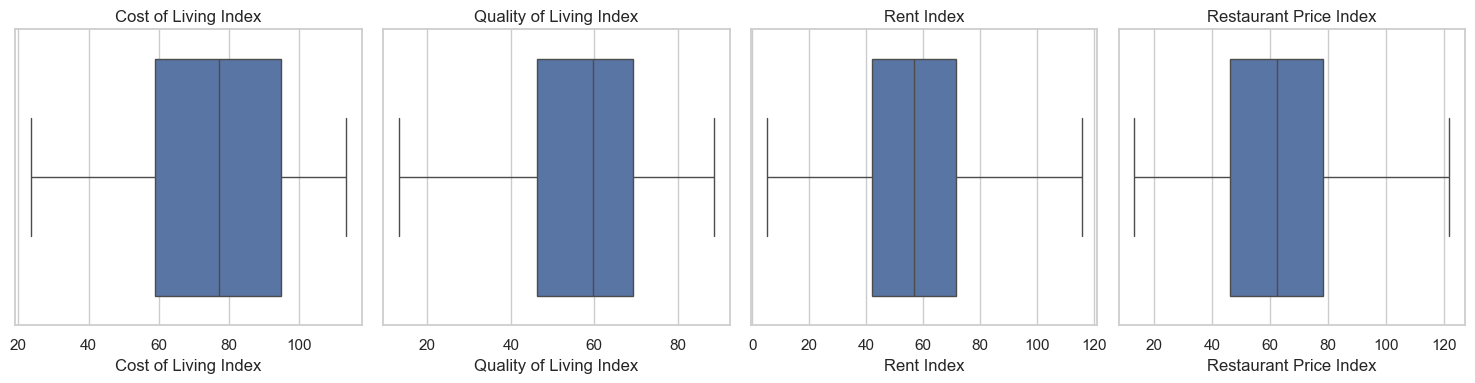

In [22]:
# Re-creating the box plots as before to demonstreate outlier capping:

# inspect the distribution of the remaining numeric columns using boxplots to identify outliers and understand the spread of the data.

# Box -> Middle 50% of values
# Line inside the box ->	Median—the middle value
# Whiskers->Range defined by the boxplot rule
# Dots beyond the whiskers -> Potential outliers to investigate

fig, axes = plt.subplots(1, 4, figsize=(15, 4))

sns.boxplot(x=df_clean["cost_of_living_index"], ax=axes[0])
axes[0].set_title("Cost of Living Index")
axes[0].set_xlabel("Cost of Living Index")

sns.boxplot(x=df_clean["quality_of_life_index"], ax=axes[1])
axes[1].set_title("Quality of Living Index")
axes[1].set_xlabel("Quality of Living Index")

sns.boxplot(x=df_clean["rent_index"], ax=axes[2])
axes[2].set_title("Rent Index")
axes[2].set_xlabel("Rent Index")

sns.boxplot(x=df_clean["restaurant_price_index"], ax=axes[3])
axes[3].set_title("Restaurant Price Index")
axes[3].set_xlabel("Restaurant Price Index")

plt.tight_layout()
plt.savefig(FIG_DIR / "01_BoxPlot.png") #save fig
plt.show()


In [23]:
# Initiating missing value analysis
missing_report(df_clean).head(12)

,n_missing,pct_missing
internet_speed_mbps,11,3.72
climate_index,11,3.72
traffic_commute_index,11,3.72
housing_price_to_income_ratio,11,3.72
avg_monthly_net_salary_usd,11,3.72
city_id,0,0.00
city,0,0.00
quality_of_life_index,0,0.00
pollution_index,0,0.00
safety_index,0,0.00


In [24]:
## Imputing missing values with sub region median


# 2. Define the 5 features with missing values
cols_to_impute = ['internet_speed_mbps', 'climate_index', 'traffic_commute_index', 'housing_price_to_income_ratio', 'avg_monthly_net_salary_usd']

# 3. Loop through each column and fill missing values with the sub region median
for col in cols_to_impute:
    # Calculate median for each sub region and align it with the original DataFrame rows
    sub_region_median = df.groupby('subregion')[col].transform('median')
    
    # Fill missing values in the column using the calculated group medians
    df_clean[col] = df_clean[col].fillna(sub_region_median)

# Print the result
print(df_clean)

     city_id        city               country   region  \
0        112     Abidjan         Cote d'Ivoire   Africa   
1        112     Abidjan         Cote d'Ivoire   Africa   
2         76   Abu Dhabi  United Arab Emirates     Asia   
3         76   Abu Dhabi  United Arab Emirates     Asia   
4         99       Abuja               Nigeria   Africa   
..       ...         ...                   ...      ...   
291       93  Wellington           New Zealand  Oceania   
292      120      Zagreb               Croatia   Europe   
293      120      Zagreb               Croatia   Europe   
294       29      Zurich           Switzerland   Europe   
295       29      Zurich           Switzerland   Europe   

                     subregion  development_tier  population_millions  \
0               Western Africa                 4                 4.89   
1               Western Africa                 4                 4.89   
2                 Western Asia                 1                 3.22   

In [25]:
key_numeric = df_clean.select_dtypes(include="number").columns.tolist()
key_numeric

stats = df_clean[key_numeric].describe().T

stats["skewness"] = df_clean[key_numeric].skew()
stats

,count,mean,std,min,25%,50%,75%,max,skewness
city_id,296.00,74.50,42.80,1.00,37.75,74.50,111.25,148.00,0.00
development_tier,296.00,2.26,1.13,1.00,1.00,2.00,3.00,4.00,0.22
population_millions,296.00,4.21,3.14,0.31,1.94,3.13,5.60,11.10,1.06
cost_of_living_index,296.00,75.16,22.31,23.54,58.85,76.97,94.70,113.29,-0.43
rent_index,296.00,57.61,21.33,5.02,42.03,56.93,71.44,115.57,0.25
groceries_index,296.00,65.30,20.89,16.79,51.17,66.70,82.23,119.62,-0.19
restaurant_price_index,296.00,62.07,21.83,13.30,46.34,62.34,78.44,121.85,0.17
local_purchasing_power_index,296.00,78.71,26.25,9.89,59.38,81.91,99.31,127.65,-0.33
avg_monthly_net_salary_usd,296.00,"4,239.66","1,616.90",359.07,"2,920.26","4,480.37","5,696.74","6,967.19",-0.41
housing_price_to_income_ratio,296.00,13.59,4.35,3.00,10.36,13.80,16.68,25.79,0.06


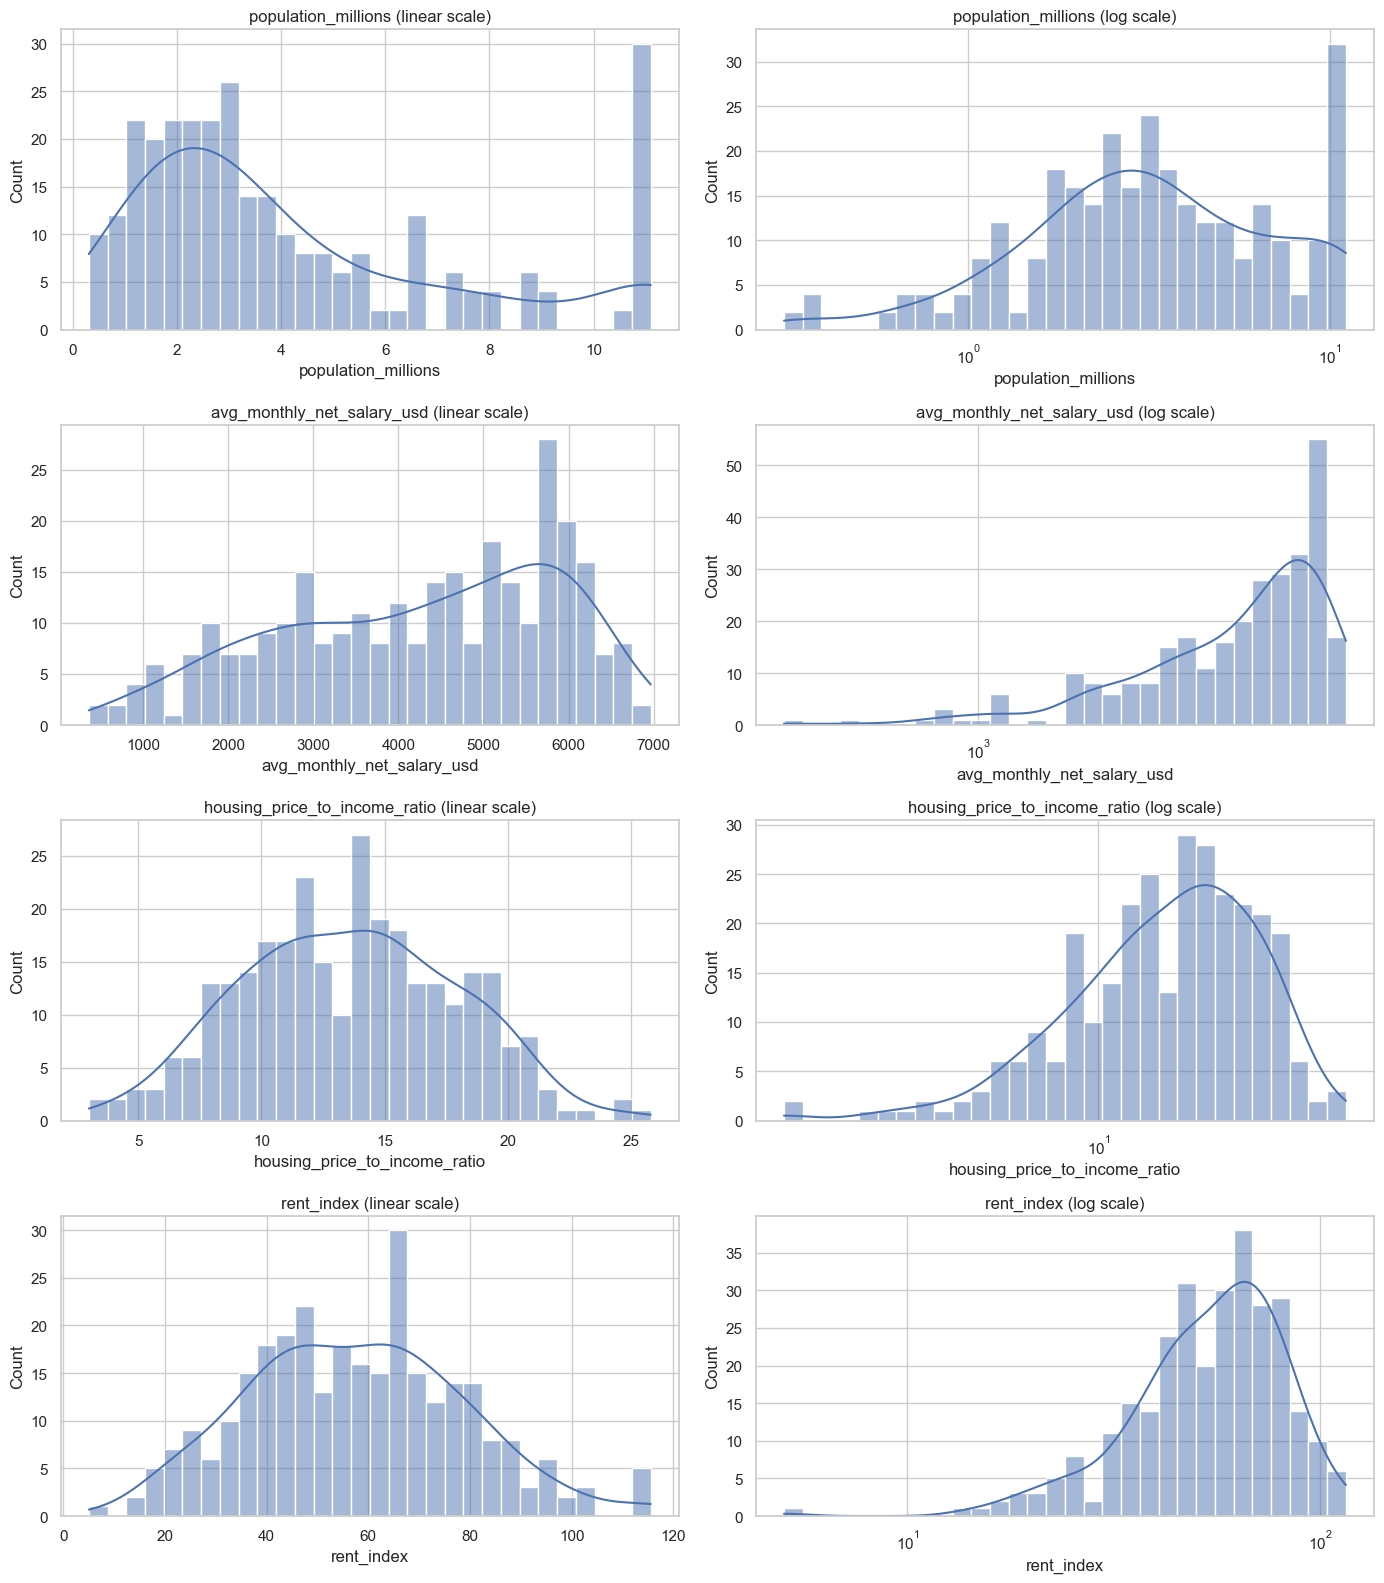

In [26]:
log_cols = ["population_millions", "avg_monthly_net_salary_usd",
            "housing_price_to_income_ratio", "rent_index"]

fig, axes = plt.subplots(len(log_cols), 2, figsize=(14, 4 * len(log_cols)), squeeze=False)

for i, col in enumerate(log_cols):
    data = df_clean[col].dropna()          # remove NaN first

    sns.histplot(data, bins=30, kde=True, ax=axes[i, 0])
    axes[i, 0].set_title(f"{col} (linear scale)")

    if (data > 0).all():
        sns.histplot(data, bins=30, kde=True, log_scale=True, ax=axes[i, 1])
        axes[i, 1].set_title(f"{col} (log scale)")
    else:
        axes[i, 1].set_title(f"{col} (log scale not possible)")
        axes[i, 1].axis("off")

plt.tight_layout()
plt.show()

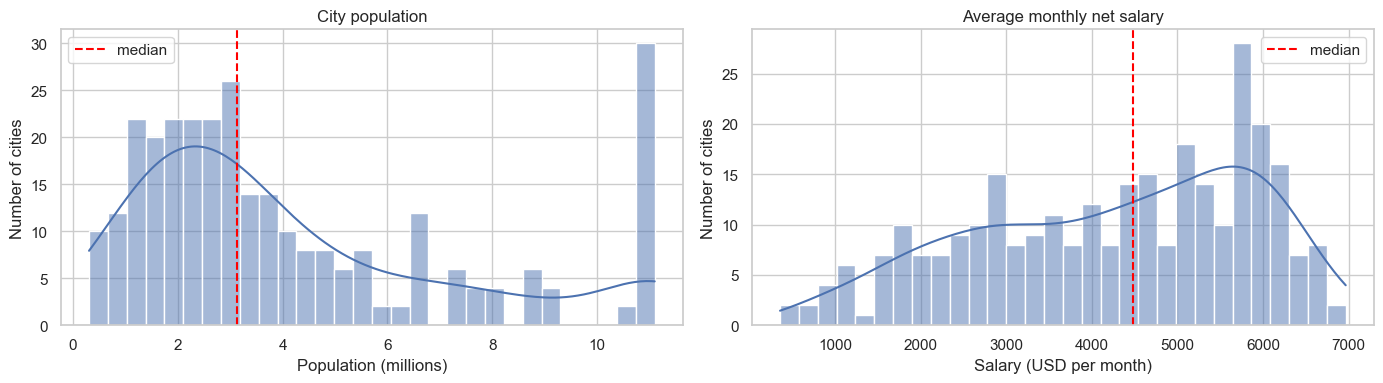

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Left: city size
pop = df_clean["population_millions"].dropna()
sns.histplot(pop, bins=30, kde=True, ax=axes[0])
axes[0].axvline(pop.median(), color="red", linestyle="--", label="median")
axes[0].set_title("City population")
axes[0].set_xlabel("Population (millions)")
axes[0].set_ylabel("Number of cities")
axes[0].legend()

# Right: income
sal = df_clean["avg_monthly_net_salary_usd"].dropna()
sns.histplot(sal, bins=30, kde=True, ax=axes[1])
axes[1].axvline(sal.median(), color="red", linestyle="--", label="median")
axes[1].set_title("Average monthly net salary")
axes[1].set_xlabel("Salary (USD per month)")
axes[1].set_ylabel("Number of cities")
axes[1].legend()

plt.tight_layout()
plt.show()

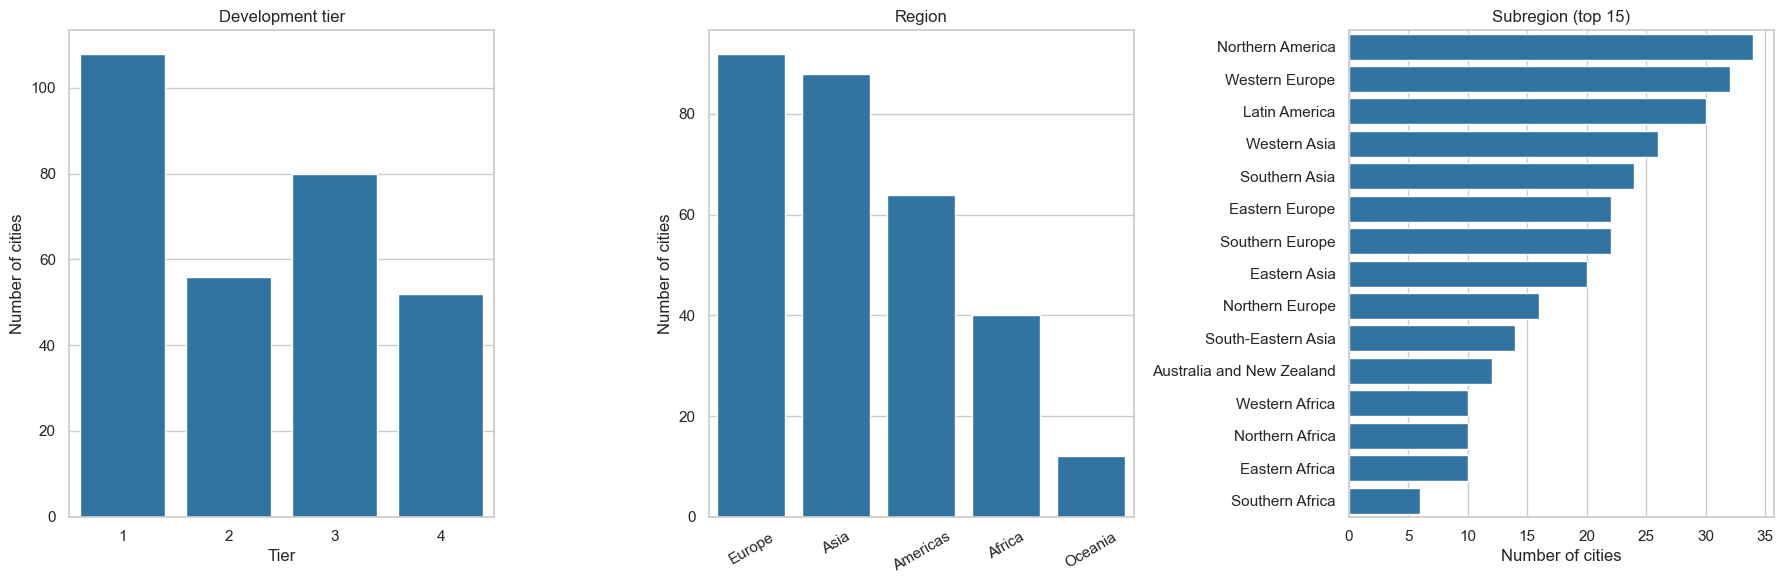

In [29]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# Ordered category: keep natural order
sns.countplot(data=df_clean, x="development_tier", color="tab:blue", ax=axes[0])
axes[0].set_title("Development tier")
axes[0].set_xlabel("Tier")
axes[0].set_ylabel("Number of cities")

# Sorted by frequency
sns.countplot(data=df_clean, x="region",
              order=df_clean["region"].value_counts().index,
              color="tab:blue", ax=axes[1])
axes[1].set_title("Region")
axes[1].set_xlabel("")
axes[1].set_ylabel("Number of cities")
axes[1].tick_params(axis="x", rotation=30)

# Horizontal bars, top 15
top_subregions = df_clean["subregion"].value_counts().head(15).index
sns.countplot(data=df_clean, y="subregion", order=top_subregions,
              color="tab:blue", ax=axes[2])
axes[2].set_title("Subregion (top 15)")
axes[2].set_ylabel("")
axes[2].set_xlabel("Number of cities")

plt.tight_layout()
plt.show()

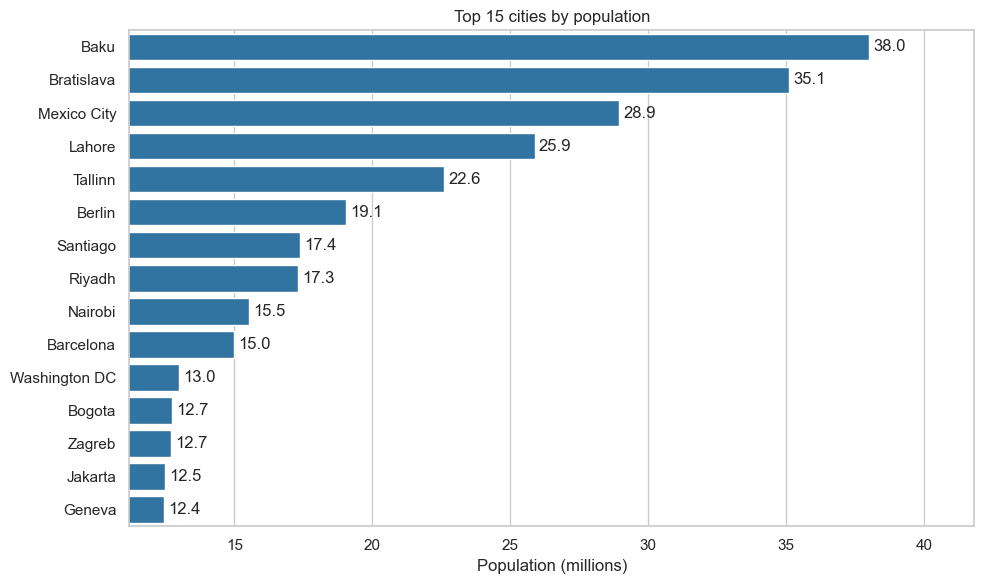

The top 15 cities hold 39% of the total population in this dataset


In [34]:
metric = "population_millions"

cities = (df.drop_duplicates(subset=["city", "country"])
            .set_index("city")[metric])
top_cities = cities.nlargest(15)

fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(x=top_cities.values, y=top_cities.index, color="tab:blue", ax=ax)
ax.set_xlim(left=top_cities.min() * 0.9, right=top_cities.max() * 1.1)
ax.bar_label(ax.containers[0], fmt="%.1f", padding=3)
ax.set_title("Top 15 cities by population")
ax.set_xlabel("Population (millions)")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

share = top_cities.sum() / cities.sum()
print(f"The top 15 cities hold {share:.0%} of the total population in this dataset")

C:\Users\breno\AppData\Local\Temp\ipykernel_5372\3735446459.py:17: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.nlargest(5, "avg_monthly_net_salary_usd")))


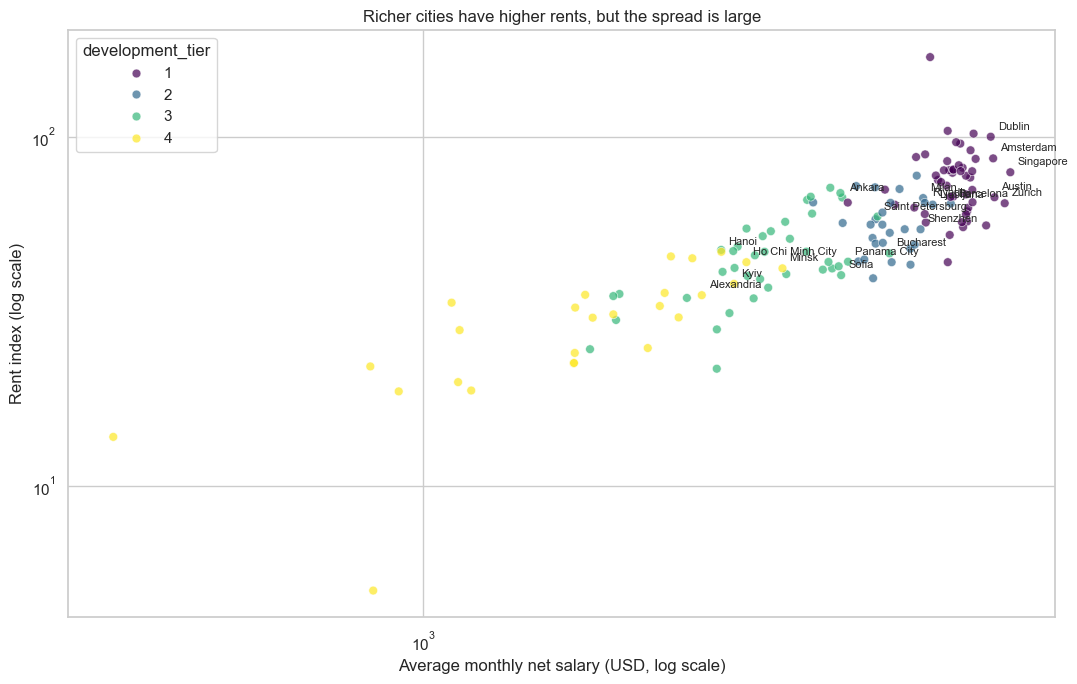

In [36]:
# One row per city, no missing values in the plotted columns
plot_df = (df.drop_duplicates(subset=["city", "country"])
             .dropna(subset=["avg_monthly_net_salary_usd", "rent_index"]))

fig, ax = plt.subplots(figsize=(11, 7))
sns.scatterplot(data=plot_df, x="avg_monthly_net_salary_usd", y="rent_index",
                hue="development_tier", palette="viridis",
                alpha=0.7, s=40, ax=ax)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_title("Richer cities have higher rents, but the spread is large")
ax.set_xlabel("Average monthly net salary (USD, log scale)")
ax.set_ylabel("Rent index (log scale)")

# Label the five highest-paid cities in EACH development tier
labels = (plot_df.groupby("development_tier", group_keys=False)
                 .apply(lambda g: g.nlargest(5, "avg_monthly_net_salary_usd")))

for _, r in labels.iterrows():
    ax.annotate(r["city"], (r["avg_monthly_net_salary_usd"], r["rent_index"]),
                xytext=(5, 5), textcoords="offset points", fontsize=8)

plt.tight_layout()
# save_fig("03_salary_vs_rent")   # uncomment to save
plt.show()

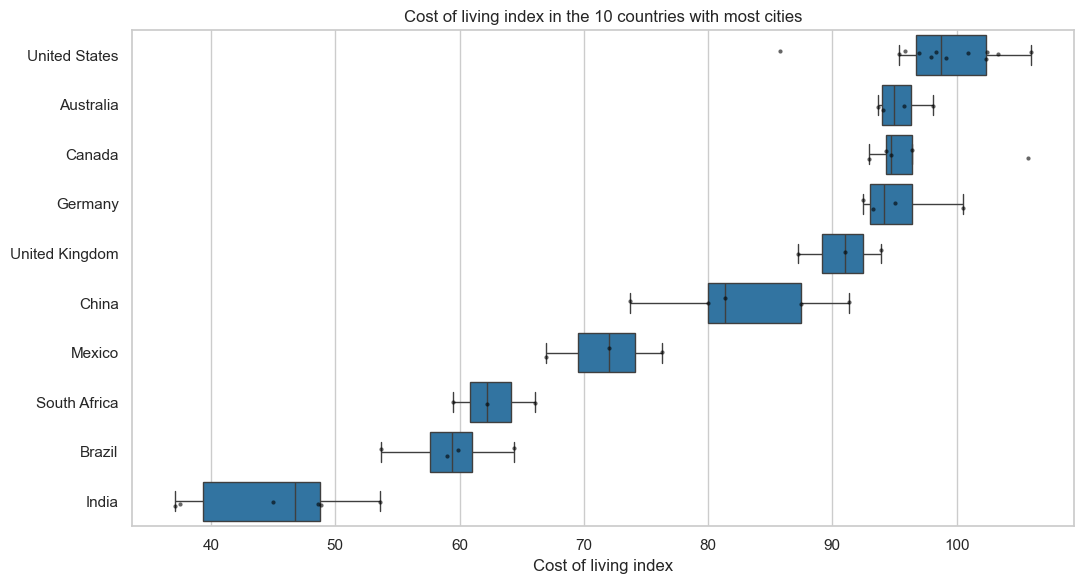

In [37]:
cities = df.drop_duplicates(subset=["city", "country"])

top10_countries = cities["country"].value_counts().head(10).index
in_top10 = cities[cities["country"].isin(top10_countries)]

metric = "cost_of_living_index"   # or rent_index, groceries_index, restaurant_price_index

country_order = (in_top10.groupby("country")[metric]
                         .median().sort_values(ascending=False).index)

fig, ax = plt.subplots(figsize=(11, 6))
sns.boxplot(data=in_top10, x=metric, y="country", order=country_order,
            showfliers=False, color="tab:blue", ax=ax)
sns.stripplot(data=in_top10, x=metric, y="country", order=country_order,
              color="black", size=3, alpha=0.6, ax=ax)
ax.set_title("Cost of living index in the 10 countries with most cities")
ax.set_xlabel("Cost of living index")
ax.set_ylabel("")
plt.tight_layout()
# save_fig("04_cost_of_living_by_country")
plt.show()

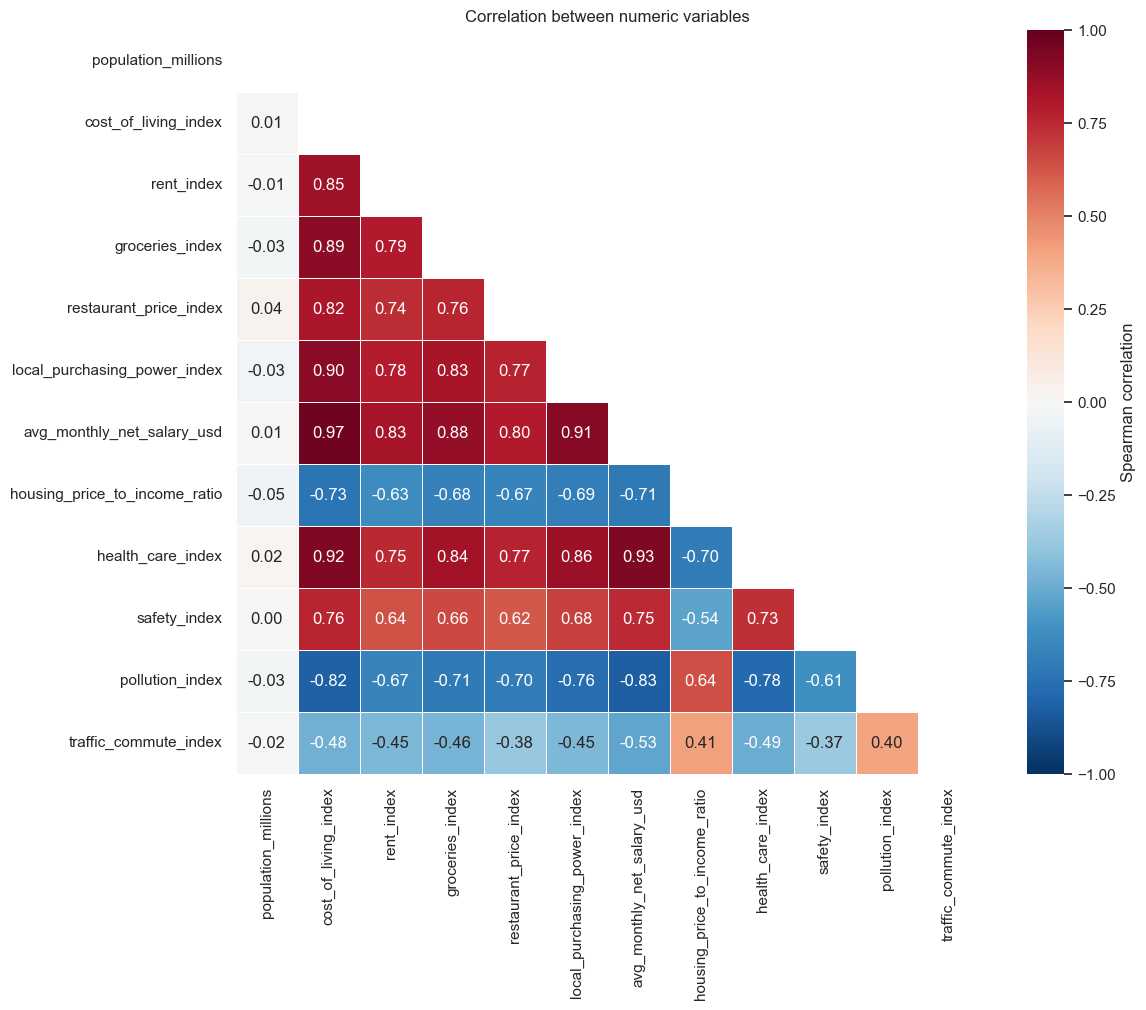

avg_monthly_net_salary_usd       0.97
health_care_index                0.92
local_purchasing_power_index     0.90
groceries_index                  0.89
rent_index                       0.85
restaurant_price_index           0.82
safety_index                     0.76
population_millions              0.01
traffic_commute_index           -0.48
housing_price_to_income_ratio   -0.73
pollution_index                 -0.82
Name: cost_of_living_index, dtype: float64

In [38]:
cities = df.drop_duplicates(subset=["city", "country"])

corr_columns = [
    "population_millions", "cost_of_living_index", "rent_index", "groceries_index",
    "restaurant_price_index", "local_purchasing_power_index", "avg_monthly_net_salary_usd",
    "housing_price_to_income_ratio", "health_care_index", "safety_index",
    "pollution_index", "traffic_commute_index",
]
corr = cities[corr_columns].corr(method="spearman")

mask = np.triu(np.ones_like(corr, dtype=bool))

fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1,
            square=True, linewidths=0.5, cbar_kws={"label": "Spearman correlation"}, ax=ax)
ax.grid(False)
ax.set_title("Correlation between numeric variables")
plt.tight_layout()
# save_fig("07_correlation_heatmap")
plt.show()

# Correlations with one target, sorted
target = "cost_of_living_index"
corr[target].drop(target).sort_values(ascending=False)